In [3]:
import pandas as pd
from pathlib import Path
from openpyxl import load_workbook
import seaborn as sns
import matplotlib.pyplot as plt


DATA_DIR = Path("../data")
CLEANED_DATA_PATH = DATA_DIR / "processed" / "mentalhealth2to27april2025_cleaned.csv"
QUESTION_LOOKUP_PATH = DATA_DIR / "processed" / "table_questions.csv"

In [4]:

questions_df = pd.read_csv(QUESTION_LOOKUP_PATH)

In [5]:
df = pd.read_csv(CLEANED_DATA_PATH)

In [8]:
df.dtypes

source_table                           str
breakdown_category                     str
breakdown                              str
response_options                       str
estimate_(%)                       float64
lcl                                float64
ucl                                float64
sample_size                          int64
weighted_count                       int64
estimate_(mean_score_out_of_10)    float64
notes                                  str
is_suppressed                         bool
dtype: object

In [82]:
questions_df[questions_df.source_table.isin(["Table_2", "Table_5", "Table_11"])]

,source_table,question
1,Table_2,"Which of the following, if any, have you been ..."
4,Table_5,In general how much do you trust most people? ...
10,Table_11,And how often do you feel lonely?


In [80]:
df = pd.read_csv(CLEANED_DATA_PATH)
df[df.source_table.isin(["Table_5", "Table_11"])].sample(n=3, random_state = 10)

,source_table,breakdown_category,breakdown,response_options,estimate_(%),lcl,ucl,sample_size,weighted_count,estimate_(mean_score_out_of_10),notes,is_suppressed
558,Table_11,Depression indicator,No or mild symptoms,Never,21.0,19.0,23.0,4010,43893248,NaN,NaN,False
508,Table_11,Age bands,16 to 29,Hardly ever or never,29.0,23.0,35.0,260,9933335,NaN,[note 4],False
233,Table_5,Age bands,50 to 69,High,66.0,63.0,69.0,1710,16669073,NaN,NaN,False


In [26]:
df = df.merge(questions_df, on="source_table", how="left")
df.insert(0, "question", df.pop("question"))

In [58]:
headline = { "Table_6": "strongly agree or agree",
            "Table_7": "strongly agree or agree"}

q1 = df[(df.breakdown_category == "Depression indicator")
        & (df.response_options.str.lower() == df.source_table.map(headline))]

In [31]:
q1

,question,source_table,breakdown_category,breakdown,response_options,estimate_(%),lcl,ucl,sample_size,weighted_count,estimate_(mean_score_out_of_10),notes,is_suppressed
293,To what extent do you agree or disagree with t...,Table_6,Depression indicator,No or mild symptoms,Strongly agree or Agree,57.0,55.0,60.0,4010,43893248,NaN,[note 4],False
300,To what extent do you agree or disagree with t...,Table_6,Depression indicator,Moderate to severe symptoms,Strongly agree or Agree,35.0,30.0,40.0,590,9946444,NaN,[note 4],False
356,To what extent do you agree or disagree with t...,Table_7,Depression indicator,No or mild symptoms,Strongly Agree or Agree,90.0,88.0,91.0,4010,43884384,NaN,[note 4],False
363,To what extent do you agree or disagree with t...,Table_7,Depression indicator,Moderate to severe symptoms,Strongly Agree or Agree,70.0,65.0,76.0,590,9946444,NaN,[note 4],False


C:\Users\Tamsin\AppData\Local\Temp\ipykernel_36704\1470398166.py:6: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  ax = sns.barplot(data=plot_df, x="estimate_(%)", y="question", hue="breakdown", palette=palette)


[Text(0.5, 0, '% respondents that strongly agree or agree'), Text(0, 0.5, '')]

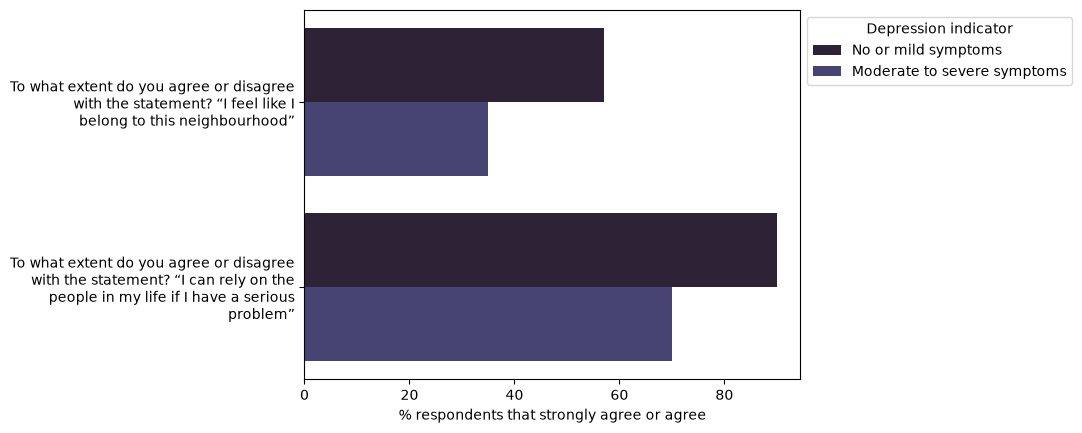

In [51]:
import textwrap

palette = sns.color_palette("mako")
plot_df = q1.copy()
plot_df["question"] = plot_df["question"].apply(lambda s: textwrap.fill(s, width=40))
ax = sns.barplot(data=plot_df, x="estimate_(%)", y="question", hue="breakdown", palette=palette)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), title="Depression indicator")
ax.set(xlabel="% respondents that strongly agree or agree", ylabel="")